# 1. Objective

Can we actually predict apartment prices in Buenos Aires based on Characteristics like size, type and location?

# 2. Problem Statement

This model helps homebuyers determine an appropriate offer when purchasing a property. It predicts apartment transaction prices in USD in Buenos Aires City. To evaluate its effectiveness, the project uses an \(R^2\) score of at least 70%, based on general real estate applications, and targets MAE and RMSE values below 10% of the median apartment price. The project is limited to three models: Linear Regression, Lasso Regression, and Ridge Regression. Their performance is compared against a baseline model that predicts the average apartment price.

# 3. Initial Hypothesis

Apartment prices in Buenos Aires City can be partly predicted from their characteristics. I expect at least one of Linear Regression, Ridge or Lasso to reach R² ≥ 0.70 on the test set and to beat the median-price baseline on both MAE and RMSE. I expect the MAE and RMSE targets of 10% of the median price to be the hardest to meet, and I think they will probably be missed.
 
My reasoning is that surface area is the strongest driver of price, since larger apartments cost more, so it should explain a large share of the variation. Location should add explanatory power because prices differ a lot between neighbourhoods, but a linear model cannot capture price jumping between areas. This is why I expect good overall fit but large individual errors. Property type will add little if the filtered data contains only apartments, because a variable that doesn’t vary cannot explain price differences. Other columns such as rooms, floor and expenses may contribute.

The hypothesis is wrong if no model reaches R² ≥ 0.70 on the test set, or if the models fail to beat the baseline on test MAE and RMSE

# 4. Hypothesis Tree

Root: Apartment prices in Buenos Aires City can be partly predicted from property characteristics using linear models.

B1: Predictive Performance

- B1.1: Compare each model’s test \\(R^2\\) against the threshold of 0.70.
- B1.2: Compare each model’s test MAE and RMSE against the median-price baseline.

B2: Predictive Value of Property Characteristics

- B2.1: Measure surface-area importance using permutation importance on the test data.
- B2.2: Compare model performance with and without location features to assess their predictive contribution.
- B2.3: Check whether property type varies across observations; if it is constant, it cannot explain price differences.

B3: Limitations of Linear Models

\- B3.1: Plot residuals against predicted prices to identify systematic patterns that may indicate nonlinear relationships.

# 5. Priority Tree

Priority 1: Data checks

Priority 2: B1a, R² on the test set - what it is: at least one model reaches test R² ≥ 0.70.

Priority 3: B1b, beating the baseline - what it is: at least one model beats the median-price baseline on test MAE and RMSE.

# 6. Loading Libraries

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

# 7. Loading data

In [58]:
df1=pd.read_csv("buenos-aires-real-estate-1.csv")
df1.columns=df1.columns.str.strip().str.lower()

df2=pd.read_csv("buenos-aires-real-estate-2.csv")
df2.columns=df2.columns.str.strip().str.lower()

df3=pd.read_csv("buenos-aires-real-estate-3.csv")
df3.columns=df3.columns.str.strip().str.lower()

df4=pd.read_csv("buenos-aires-real-estate-4.csv")
df4.columns=df4.columns.str.strip().str.lower()

df5=pd.read_csv("buenos-aires-real-estate-5.csv")
df5.columns=df4.columns.str.strip().str.lower()


In [59]:
df=pd.concat([df1,df2,df3,df4,df5])
display(df)

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.00,180000.00,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.00,250000.00,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.00,410000.00,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.00,180000.00,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.60,129000.00,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8600,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|San Fernan...,"-34.4498923,-58.5333348",191800.0,USD,2908148.32,191800.00,68.0,54.0,2820.588235,3551.851852,1.0,NaN,NaN,http://victoria.properati.com.ar/nj3n_venta_de...
8601,sell,house,|Argentina|Bs.As. G.B.A. Zona Norte|Vicente Ló...,"-34.5356489416,-58.4981208948",550000.0,USD,8339320.00,550000.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://florida.properati.com.ar/j5jl_venta_cas...
8602,sell,apartment,|Argentina|Capital Federal|Belgrano|,"-34.5522215,-58.4448022",560000.0,USD,8490944.00,560000.00,137.0,126.0,4087.591241,4444.444444,NaN,3.0,7000.0,http://belgrano.properati.com.ar/12pck_venta_d...
8603,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|General Sa...,"-34.580145797,-58.5542081641",180000.0,ARS,179500.37,11838.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://san-martin.properati.com.ar/edzj_venta_...


In [60]:
df.to_csv("combined-buenos-aires-real-estate.csv",index=False)

# 8. Exploratory Data Analysis (EDA)

## 8.1 Univariate Analysis

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43029 entries, 0 to 8604
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   43029 non-null  object 
 1   property_type               43029 non-null  object 
 2   place_with_parent_names     43029 non-null  object 
 3   lat-lon                     34734 non-null  object 
 4   price                       38073 non-null  float64
 5   currency                    38072 non-null  object 
 6   price_aprox_local_currency  38073 non-null  float64
 7   price_aprox_usd             38073 non-null  float64
 8   surface_total_in_m2         29871 non-null  float64
 9   surface_covered_in_m2       36420 non-null  float64
 10  price_usd_per_m2            24449 non-null  float64
 11  price_per_m2                32642 non-null  float64
 12  floor                       6505 non-null   float64
 13  rooms                       23806 non

In [62]:
df.describe(include="object")

,operation,property_type,place_with_parent_names,lat-lon,currency,properati_url
count,43029,43029,43029,34734,38072,43029
unique,1,4,499,25747,2,43029
top,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,"-34.6036844,-58.3815591",USD,http://villa-crespo.properati.com.ar/12egq_ven...
freq,43029,23228,2370,273,36394,1


In [63]:
df.describe()

,price,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses
count,3.807300e+04,3.807300e+04,3.807300e+04,29871.000000,36420.000000,24449.000000,32642.000000,6505.000000,23806.000000,4.452000e+03
mean,2.959661e+05,3.537121e+06,2.332824e+05,269.157578,244.493904,1718.387879,3737.943768,10.789700,3.058305,4.499551e+15
std,4.940386e+05,4.781742e+06,3.153684e+05,1686.328201,10371.179349,1497.571317,11657.891695,79.735358,1.412714,3.002249e+17
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.056686,1.000000,1.000000,1.000000e+00
25%,9.500000e+04,1.364616e+06,9.000000e+04,47.000000,46.000000,931.372549,1454.545455,2.000000,2.000000,8.000000e+02
50%,1.550000e+05,2.198548e+06,1.450000e+05,90.000000,76.000000,1600.000000,1964.285714,3.000000,3.000000,1.600000e+03
75%,2.950000e+05,3.942224e+06,2.600000e+05,248.000000,160.000000,2193.668000,2666.666667,6.000000,4.000000,3.100000e+03
max,1.500000e+07,2.274360e+08,1.500000e+07,192014.000000,987897.000000,54990.000000,749000.000000,2103.000000,32.000000,2.003200e+19


In [64]:
df.isnull().sum()

operation                         0
property_type                     0
place_with_parent_names           0
lat-lon                        8295
price                          4956
currency                       4957
price_aprox_local_currency     4956
price_aprox_usd                4956
surface_total_in_m2           13158
surface_covered_in_m2          6609
price_usd_per_m2              18580
price_per_m2                  10387
floor                         36524
rooms                         19223
expenses                      38577
properati_url                     0
dtype: int64

In [66]:
df["state"]=df["place_with_parent_names"].str.split("|").str[2]

df["neighborhood"]=df["place_with_parent_names"].str.split("|").str[3]

df[["lat","lon"]]=df["lat-lon"].str.split(",",expand=True)

In [67]:
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url,state,neighborhood,lat,lon
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...,Capital Federal,Villa Crespo,-34.6047834183,-58.4586812499
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...,Bs.As. G.B.A. Zona Oeste,La Matanza,NaN,NaN
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...,Bs.As. G.B.A. Zona Oeste,Morón,-34.6497002,-58.658073
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...,Bs.As. G.B.A. Zona Oeste,Tres de Febrero,-34.5957086,-58.5669503
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...,Capital Federal,Chacarita,-34.5846508988,-58.4546932614


In [68]:
df=df[df["property_type"]=="apartment"]

df=df[df["state"]=="Capital Federal"]



In [69]:
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url,state,neighborhood,lat,lon
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...,Capital Federal,Villa Crespo,-34.6047834183,-58.4586812499
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...,Capital Federal,Chacarita,-34.5846508988,-58.4546932614
9,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6389789,-58.500115",87000.0,USD,1319128.8,87000.0,48.0,42.0,1812.500000,2071.428571,NaN,NaN,NaN,http://villa-luro.properati.com.ar/12m82_venta...,Capital Federal,Villa Luro,-34.6389789,-58.500115
11,sell,apartment,|Argentina|Capital Federal|Once|,"-34.6050060697,-58.4001162302",60000.0,USD,909744.0,60000.0,28.0,28.0,2142.857143,2142.857143,NaN,1.0,NaN,http://once.properati.com.ar/zz0q_venta_depart...,Capital Federal,Once,-34.6050060697,-58.4001162302
18,sell,apartment,|Argentina|Capital Federal|Belgrano|,"-34.5646269,-58.4412741",600000.0,USD,9097440.0,600000.0,220.0,NaN,2727.272727,NaN,NaN,5.0,NaN,http://belgrano.properati.com.ar/jvge_venta_de...,Capital Federal,Belgrano,-34.5646269,-58.4412741


In [70]:
df=df.drop(["operation","properati_url","lat-lon","property_type","place_with_parent_names","price","currency","price_aprox_local_currency","price_usd_per_m2","price_per_m2","state"],axis=1)

In [71]:
df.head()

,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,floor,rooms,expenses,neighborhood,lat,lon
0,180000.0,120.0,110.0,NaN,4.0,NaN,Villa Crespo,-34.6047834183,-58.4586812499
4,129000.0,76.0,70.0,NaN,NaN,NaN,Chacarita,-34.5846508988,-58.4546932614
9,87000.0,48.0,42.0,NaN,NaN,NaN,Villa Luro,-34.6389789,-58.500115
11,60000.0,28.0,28.0,NaN,1.0,NaN,Once,-34.6050060697,-58.4001162302
18,600000.0,220.0,NaN,NaN,5.0,NaN,Belgrano,-34.5646269,-58.4412741


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10284 entries, 0 to 8604
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        9567 non-null   float64
 1   surface_total_in_m2    7170 non-null   float64
 2   surface_covered_in_m2  9222 non-null   float64
 3   floor                  2736 non-null   float64
 4   rooms                  7854 non-null   float64
 5   expenses               2637 non-null   float64
 6   neighborhood           10284 non-null  object 
 7   lat                    9849 non-null   object 
 8   lon                    9849 non-null   object 
dtypes: float64(6), object(3)
memory usage: 803.4+ KB


In [73]:
df=df.dropna(subset=["lat","lon"])

In [75]:
df=df.dropna(subset=["price_aprox_usd"])

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9202 entries, 0 to 8604
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        9202 non-null   float64
 1   surface_total_in_m2    6503 non-null   float64
 2   surface_covered_in_m2  8399 non-null   float64
 3   floor                  2567 non-null   float64
 4   rooms                  7134 non-null   float64
 5   expenses               2517 non-null   float64
 6   neighborhood           9202 non-null   object 
 7   lat                    9202 non-null   object 
 8   lon                    9202 non-null   object 
dtypes: float64(6), object(3)
memory usage: 718.9+ KB


In [77]:
df.isnull().sum()

price_aprox_usd             0
surface_total_in_m2      2699
surface_covered_in_m2     803
floor                    6635
rooms                    2068
expenses                 6685
neighborhood                0
lat                         0
lon                         0
dtype: int64

In [78]:
df=df.drop(["surface_total_in_m2","floor","expenses"],axis=1)

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9202 entries, 0 to 8604
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        9202 non-null   float64
 1   surface_covered_in_m2  8399 non-null   float64
 2   rooms                  7134 non-null   float64
 3   neighborhood           9202 non-null   object 
 4   lat                    9202 non-null   object 
 5   lon                    9202 non-null   object 
dtypes: float64(3), object(3)
memory usage: 503.2+ KB


In [80]:
df.describe(include='all')

,price_aprox_usd,surface_covered_in_m2,rooms,neighborhood,lat,lon
count,9.202000e+03,8399.000000,7134.000000,9202,9202,9202
unique,NaN,NaN,NaN,57,6445,6447
top,NaN,NaN,NaN,Palermo,-34.6037137392,-58.3815808896
freq,NaN,NaN,NaN,1024,59,59
mean,2.009775e+05,78.086320,2.571489,NaN,NaN,NaN
std,2.679621e+05,683.445569,1.226320,NaN,NaN,NaN
min,0.000000e+00,0.000000,1.000000,NaN,NaN,NaN
25%,9.000000e+04,38.000000,2.000000,NaN,NaN,NaN
50%,1.290000e+05,52.000000,2.000000,NaN,NaN,NaN
75%,2.040000e+05,81.000000,3.000000,NaN,NaN,NaN


In [81]:
df = df.reset_index(drop=True)

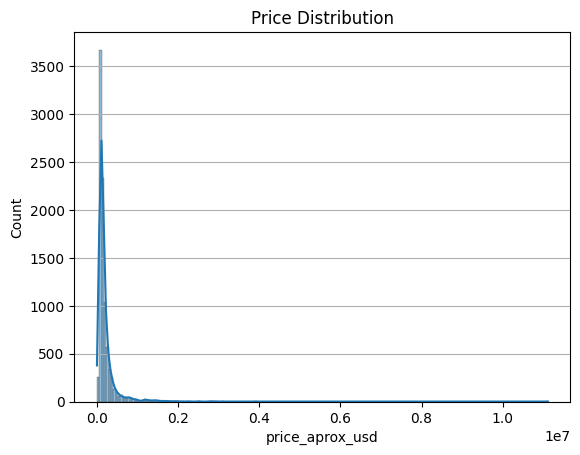

In [82]:
sns.histplot(data=df,x="price_aprox_usd",kde=True)
plt.title("Price Distribution")
plt.ylabel("Count")
plt.xlabel("price_aprox_usd")
plt.grid(axis="y")
plt.show()

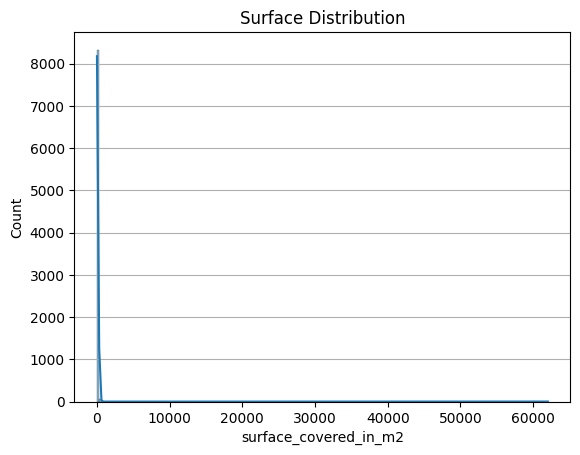

In [83]:
sns.histplot(data=df,x="surface_covered_in_m2",kde=True)
plt.title("Surface Distribution")
plt.ylabel("Count")
plt.xlabel("surface_covered_in_m2")
plt.grid(axis="y")
plt.show()

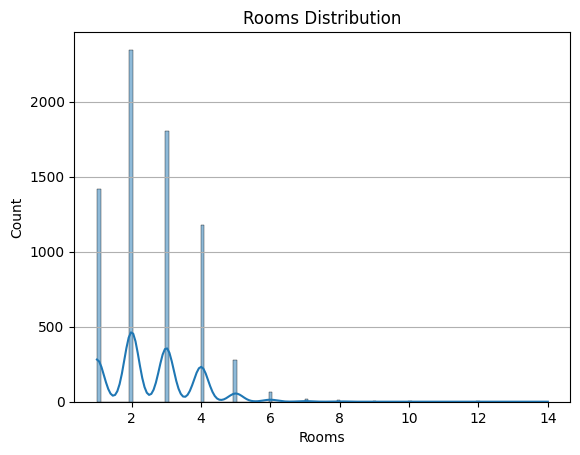

In [84]:
sns.histplot(data=df,x="rooms",kde=True)
plt.title("Rooms Distribution")
plt.ylabel("Count")
plt.xlabel("Rooms")
plt.grid(axis="y")
plt.show()

In [85]:
df.neighborhood.value_counts()

neighborhood
Palermo                  1024
Belgrano                  931
Caballito                 661
Villa Crespo              486
Almagro                   448
Villa Urquiza             448
Barrio Norte              436
Flores                    399
Recoleta                  347
Nuñez                     327
Balvanera                 316
Saavedra                  194
Puerto Madero             186
San Telmo                 184
San Cristobal             168
Barracas                  164
Congreso                  160
Monserrat                 157
Colegiales                147
Boedo                     144
Villa Luro                144
Villa del Parque          118
Villa Devoto              115
Boca                      104
Once                      101
Floresta                   93
Retiro                     84
San Nicolás                81
Centro / Microcentro       80
Parque Patricios           75
Coghlan                    75
Mataderos                  65
Paternal                   

In [86]:
print("Zero prices:", (df["price_aprox_usd"] == 0).sum())

Zero prices: 7


In [87]:
df = df[df["price_aprox_usd"] > 0].copy()

In [88]:
df["price_aprox_usd"].describe()

count    9.195000e+03
mean     2.011305e+05
std      2.680067e+05
min      5.195790e+03
25%      9.000000e+04
50%      1.290000e+05
75%      2.041854e+05
max      1.111111e+07
Name: price_aprox_usd, dtype: float64

In [89]:
df.nlargest(20, "price_aprox_usd")[["price_aprox_usd","surface_covered_in_m2","rooms","neighborhood"]]

,price_aprox_usd,surface_covered_in_m2,rooms,neighborhood
5166,11111111.0,360.0,NaN,Mataderos
860,3900000.0,630.0,5.0,Palermo
5369,3100000.0,0.0,5.0,Palermo
3853,2950000.0,354.0,4.0,Puerto Madero
7465,2900000.0,400.0,5.0,Puerto Madero
4637,2850000.0,364.0,5.0,Palermo
6457,2830000.0,310.0,5.0,Puerto Madero
4147,2800000.0,334.0,NaN,Puerto Madero
4178,2800000.0,255.0,4.0,Palermo
5362,2800000.0,320.0,4.0,Puerto Madero


In [90]:
df["price_aprox_usd"].describe(percentiles=[.10,.50, .75, .90,.92, .95, .96,.97,.98, .99, .995, .999])

count    9.195000e+03
mean     2.011305e+05
std      2.680067e+05
min      5.195790e+03
10%      7.300000e+04
50%      1.290000e+05
75%      2.041854e+05
90%      3.600000e+05
92%      4.180000e+05
95%      5.800000e+05
96%      6.800000e+05
97%      8.000000e+05
98%      9.900000e+05
99%      1.380000e+06
99.5%    1.650000e+06
99.9%    2.800000e+06
max      1.111111e+07
Name: price_aprox_usd, dtype: float64

In [95]:
df=df[df["price_aprox_usd"]<=400000].copy()

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8439 entries, 0 to 9199
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        8439 non-null   float64
 1   surface_covered_in_m2  7721 non-null   float64
 2   rooms                  6540 non-null   float64
 3   neighborhood           8439 non-null   object 
 4   lat                    8439 non-null   object 
 5   lon                    8439 non-null   object 
dtypes: float64(3), object(3)
memory usage: 461.5+ KB


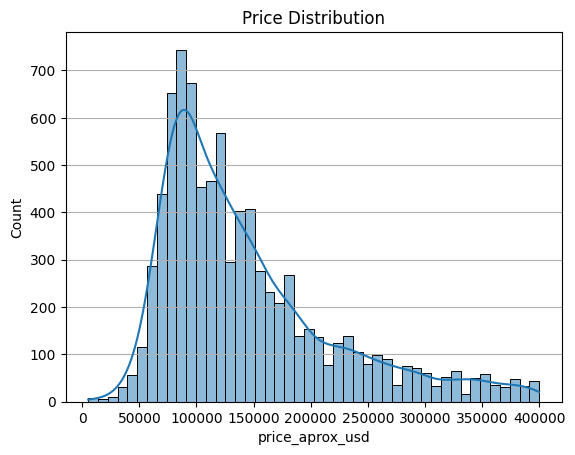

In [97]:
sns.histplot(data=df,x="price_aprox_usd",kde=True)
plt.title("Price Distribution")
plt.ylabel("Count")
plt.xlabel("price_aprox_usd")
plt.grid(axis="y")
plt.show()

In [100]:
df["surface_covered_in_m2"]=df["surface_covered_in_m2"].replace(0,np.nan)

In [101]:
print("Zero rooms:", (df["rooms"] == 0).sum())

print("Missing rooms:", df["rooms"].isna().sum())

print("Zero covered surface:",
      (df["surface_covered_in_m2"] == 0).sum())

print("Missing covered surface:",
      df["surface_covered_in_m2"].isna().sum())

Zero rooms: 0
Missing rooms: 1899
Zero covered surface: 0
Missing covered surface: 829


In [103]:
imputer=SimpleImputer(strategy="median")

df[["surface_covered_in_m2","rooms"]]=imputer.fit_transform(df[["surface_covered_in_m2","rooms"]])

In [113]:
df["surface_covered_in_m2"]=df["surface_covered_in_m2"].clip(lower=df["surface_covered_in_m2"].quantile(0.1),upper=df["surface_covered_in_m2"].quantile(0.9))
df["rooms"]=df["rooms"].clip(upper=df["rooms"].quantile(0.90))

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8439 entries, 0 to 9199
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        8439 non-null   float64
 1   surface_covered_in_m2  8439 non-null   float64
 2   rooms                  8439 non-null   float64
 3   neighborhood           8439 non-null   object 
 4   lat                    8439 non-null   object 
 5   lon                    8439 non-null   object 
dtypes: float64(3), object(3)
memory usage: 461.5+ KB


In [115]:
df.describe()

,price_aprox_usd,surface_covered_in_m2,rooms
count,8439.000000,8439.000000,8439.000000
mean,143810.043727,56.289134,2.294822
std,76290.797100,21.318971,0.894963
min,5195.790000,32.000000,1.000000
25%,89000.000000,39.000000,2.000000
50%,120000.000000,50.000000,2.000000
75%,176900.000000,70.000000,3.000000
max,400000.000000,99.000000,4.000000


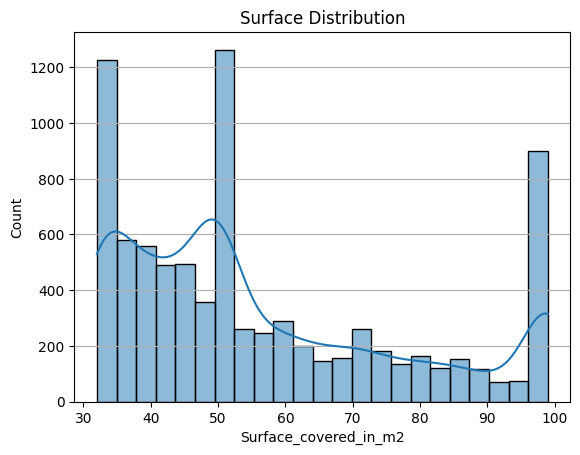

In [109]:
sns.histplot(data=df,x="surface_covered_in_m2",kde=True)
plt.title("Surface Distribution")
plt.ylabel("Count")
plt.xlabel("Surface_covered_in_m2")
plt.grid(axis="y")
plt.show()

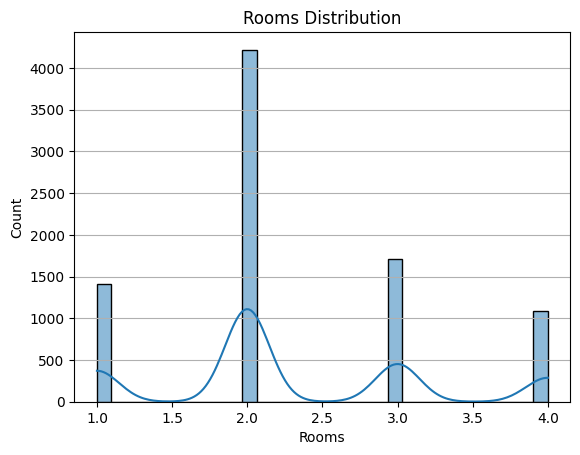

In [116]:
sns.histplot(data=df,x="rooms",kde=True)
plt.title("Rooms Distribution")
plt.ylabel("Count")
plt.xlabel("Rooms")
plt.grid(axis="y")
plt.show()

In [117]:
df.to_csv("cleaned-buenos-aires-real-estate.csv",index=False)

## 8.2 Bivariate Analysis

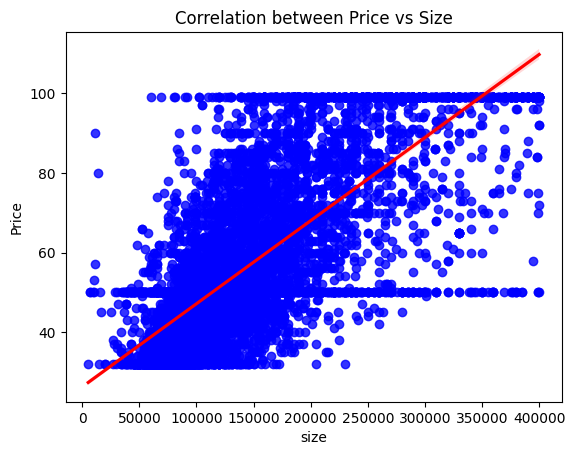

In [119]:
sns.regplot(data=df,x="price_aprox_usd",y="surface_covered_in_m2",ci=95,  color="blue",line_kws={"color": "red"})
plt.title("Correlation between Price vs Size")
plt.ylabel("Price")
plt.xlabel("size")
plt.show()

In [121]:
b1=df["price_aprox_usd"].corr(df["surface_covered_in_m2"])
print(b1)

0.7463296471906985


In [127]:
b2=df.groupby("neighborhood").apply(lambda x: x["surface_covered_in_m2"].corr(x["price_aprox_usd"])).sort_values(ascending=False).aggregate(["median", "std","mean"])
print(b2)

median    0.788814
std       0.121945
mean      0.762877
dtype: float64


c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Suleiman Umar Farouk\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Suleiman Umar Farouk\AppData\Local\Temp\ipykernel_32172\1679754679.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  b2=df.groupby("neighborhood").apply(lambda x: x["surface_covered_in_m2"].corr(x["price_aprox_usd"])).sort_values(ascending=False).aggregate(["median", "std","mean"])


# 9. Data Diagnosis and Decision Making

The numerical variables will be standardised using `StandardScaler`, while categorical variables will be transformed using `OneHotEncoder` to convert them into numerical representations suitable for model training.

# 10. Features Selection

In [129]:
features=["rooms","lat","lon","surface_covered_in_m2","neighborhood"]
num_features=["rooms","lat","lon","surface_covered_in_m2"]
cat_features=["neighborhood"]
x=df[features]
y=df["price_aprox_usd"]


# 11. Data Splitting

In [130]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

# 12. Data Transformation

In [131]:
num_transformer=Pipeline([("scaler",StandardScaler())])
cat_transformer=Pipeline([("onehote",OneHotEncoder(categories="auto", handle_unknown="ignore",sparse_output=False))])
preprocessor=ColumnTransformer([("num",num_transformer,num_features),("cat",cat_transformer,cat_features)])
x_train_p=preprocessor.fit_transform(x_train)
x_test_p=preprocessor.transform(x_test)

# 13. Baseline Model

In [133]:
average_y=y_train.mean()
baseline_pred=np.full(len(y_test),average_y)
baseline_mae=mean_absolute_error(y_test,baseline_pred)
baseline_rmse=np.sqrt(mean_squared_error(y_test,baseline_pred))
baseline_r2=r2_score(y_test,baseline_pred)

print(baseline_mae)
print(baseline_rmse)
print(baseline_r2)

58909.281716202655
76403.06201658168
-0.0006261492701351568


# 14. Advanced Models

In [ ]:
models={"Linear Regression": LinearRegression(),
        "RidgeCV": RidgeCV(),
        "LassoCV":LassoCV()}

train_results=[]
test_results=[]

for name,model in models.items():
    model.fit(x_train_p,y_train)

    y_train_pred=model.predict(x_train_p)
    y_test_pred=model.predict(x_test_p)

    train_results.append({model:name,
                          "MAE":mean_absolute_error(y_train,y_train_pred),
                          "RMSE":np.sqrt(mean_squared_error(y_train,y_train_pred)),
                          "R2":r2_score(y_train,y_train_pred)})

    test_results.append({model:name,
                         "MAE":mean_absolute_error(y_test,y_test_pred),
                         "RMSE":np.sqrt(mean_squared_error(y_test,y_test_pred)),
                         "R2":r2_score(y_test,y_test_pred)})

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Actual vs Predicted - Training
    sns.scatterplot(x=y_train, y=y_train_pred, ax=axes[0, 0], alpha=0.5)
    axes[0, 0].plot([y_train.min(), y_train.max()],[y_train.min(), y_train.max()],'r--')
    axes[0, 0].set_title(f'{name} - Training: Actual vs Predicted')
    axes[0, 0].set_xlabel('Actual Prices')
    axes[0, 0].set_ylabel('Predicted Prices')

    # Actual vs Predicted - Testing
    sns.scatterplot(x=y_test, y=y_test_pred, ax=axes[0, 1], alpha=0.5)
    axes[0, 1].plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],'r--')
    axes[0, 1].set_title(f'{name} - Testing: Actual vs Predicted')
    axes[0, 1].set_xlabel('Actual Prices')
    axes[0, 1].set_ylabel('Predicted Prices')

    # Residuals - Training
    train_residuals = y_train - y_train_pred
    sns.scatterplot(x=y_train_pred, y=train_residuals, ax=axes[1, 0], alpha=0.5)
    axes[1, 0].axhline(y=0, color='red', linestyle='--')
    axes[1, 0].set_title(f'{name} - Training Residuals')
    axes[1, 0].set_xlabel('Predicted Prices')
    axes[1, 0].set_ylabel('Residuals')

    # Residuals - Testing
    test_residuals = y_test - y_test_pred
    sns.scatterplot(x=y_test_pred, y=test_residuals, ax=axes[1, 1], alpha=0.5)
    axes[1, 1].axhline(y=0, color='red', linestyle='--')
    axes[1, 1].set_title(f'{name} - Testing Residuals')
    axes[1, 1].set_xlabel('Predicted Prices ($)')
    axes[1, 1].set_ylabel('Residuals ($)')

    plt.tight_layout()
    plt.show()

train_results_df=pd.DataFrame(train_results)
test_results_df=pd.DataFrame(test_results)            




NameError: name 'train_results' is not defined